In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dgomonov/new-york-city-airbnb-open-data/AB_NYC_2019.csv
/kaggle/input/datasets/dgomonov/new-york-city-airbnb-open-data/New_York_City_.png


In [2]:
df = pd.read_csv('/kaggle/input/datasets/dgomonov/new-york-city-airbnb-open-data/AB_NYC_2019.csv')

print("Dataset dimensions:", df.shape)
df.head()

Dataset dimensions: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [4]:
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df) * 100).round(2)
})

missing_data = missing_data.sort_values(
    by='Missing Values',
    ascending=False
)

missing_data

,Missing Values,Missing Percentage
last_review,10052,20.56
reviews_per_month,10052,20.56
host_name,21,0.04
name,16,0.03
neighbourhood_group,0,0.00
neighbourhood,0,0.00
id,0,0.00
host_id,0,0.00
longitude,0,0.00
latitude,0,0.00


In [5]:
both_missing = (df["last_review"].isna() & df["reviews_per_month"].isna()).sum()

either_missing = (df["last_review"].isna() | df["reviews_per_month"].isna()).sum()

neither_missing = (df["last_review"].notna() & df["reviews_per_month"].notna()).sum()

total_rows = len(df)

print("Rows with both fields missing:", both_missing)
print("Rows with either field missing:", either_missing)
print("Rows with neither field missing:", neither_missing)
print("Total rows in original DataFrame:", total_rows)
print("Counts are consistent:", either_missing + neither_missing == total_rows)

Rows with both fields missing: 10052
Rows with either field missing: 10052
Rows with neither field missing: 38843
Total rows in original DataFrame: 48895
Counts are consistent: True


In [6]:
missing_mask = df["last_review"].isna() & df["reviews_per_month"].isna()

zero_reviews = (missing_mask & (df["number_of_reviews"] == 0)).sum()

positive_reviews = (missing_mask & (df["number_of_reviews"] > 0)).sum()

print("Listings with both fields missing and zero reviews:", zero_reviews)
print("Listings with both fields missing and more than zero reviews:", positive_reviews)

Listings with both fields missing and zero reviews: 10052
Listings with both fields missing and more than zero reviews: 0


In [7]:
print("Missing values in name:", df["name"].isna().sum())
print("Missing values in host_name:", df["host_name"].isna().sum())

missing_info = df[df["name"].isna() | df["host_name"].isna()]

display(missing_info[[
    "id",
    "name",
    "host_id",
    "host_name",
    "number_of_reviews"
]])

Missing values in name: 16
Missing values in host_name: 21


,id,name,host_id,host_name,number_of_reviews
360,100184,Bienvenue,526653,NaN,43
2700,1449546,Cozy Studio in Flatbush,7779204,NaN,49
2854,1615764,NaN,6676776,Peter,0
3703,2232600,NaN,11395220,Anna,28
5745,4183989,SPRING in the City!! Zen-Style Tranquil Bedroom,919218,NaN,34
5775,4209595,NaN,20700823,Jesse,1
5975,4370230,NaN,22686810,Michaël,5
6075,4446862,Charming Room in Prospect Heights!,23077718,NaN,0
6269,4581788,NaN,21600904,Lucie,0
6567,4756856,NaN,1832442,Carolina,0


In [8]:
missing_hosts = df[df["host_name"].isna()]

known_names = (
    df[df["host_name"].notna()]
    .groupby("host_id")["host_name"]
    .agg(lambda names: names.unique().tolist())
)

safe_matches = missing_hosts["host_id"].map(known_names)
safe_match_mask = safe_matches.apply(
    lambda names: isinstance(names, list) and len(names) == 1
)

print("Total rows with missing host_name:", len(missing_hosts))
print("Missing host names that can be matched safely:", safe_match_mask.sum())
print("Missing host names without a unique match:", (~safe_match_mask).sum())

matches = missing_hosts[["id", "host_id", "host_name"]].copy()
matches["known_host_names"] = safe_matches
matches["safe_to_match"] = safe_match_mask
display(matches)


Total rows with missing host_name: 21
Missing host names that can be matched safely: 0
Missing host names without a unique match: 21


,id,host_id,host_name,known_host_names,safe_to_match
360,100184,526653,NaN,NaN,False
2700,1449546,7779204,NaN,NaN,False
5745,4183989,919218,NaN,NaN,False
6075,4446862,23077718,NaN,NaN,False
6582,4763327,24576978,NaN,NaN,False
8163,6292866,32722063,NaN,NaN,False
8257,6360224,33134899,NaN,NaN,False
8852,6786181,32722063,NaN,NaN,False
9138,6992973,5162530,NaN,NaN,False
9817,7556587,39608626,NaN,NaN,False


In [9]:
missing_names = df[df["name"].isna()]

display(missing_names[[
    "id",
    "host_id",
    "host_name",
    "neighbourhood",
    "room_type",
    "number_of_reviews"
]])

print("Total listings with missing names:", len(missing_names))

,id,host_id,host_name,neighbourhood,room_type,number_of_reviews
2854,1615764,6676776,Peter,Battery Park City,Entire home/apt,0
3703,2232600,11395220,Anna,East Village,Entire home/apt,28
5775,4209595,20700823,Jesse,Greenwich Village,Entire home/apt,1
5975,4370230,22686810,Michaël,Nolita,Entire home/apt,5
6269,4581788,21600904,Lucie,Williamsburg,Private room,0
6567,4756856,1832442,Carolina,Bushwick,Private room,0
6605,4774658,24625694,Josh,Washington Heights,Private room,0
8841,6782407,31147528,Huei-Yin,Williamsburg,Private room,0
11963,9325951,33377685,Jonathan,Hell's Kitchen,Entire home/apt,1
12824,9787590,50448556,Miguel,Harlem,Entire home/apt,0


Total listings with missing names: 16


In [10]:
df_cleaned = df.copy()

df_cleaned["name"] = df_cleaned["name"].fillna("Unknown listing name")
df_cleaned["host_name"] = df_cleaned["host_name"].fillna("Unknown host name")

print("Missing values in df_cleaned:")
print(df_cleaned[["name", "host_name"]].isna().sum())

print("\nMissing values in original df:")
print(df[["name", "host_name"]].isna().sum())

print("\nOriginal row count:", len(df))
print("Cleaned row count:", len(df_cleaned))

Missing values in df_cleaned:
name         0
host_name    0
dtype: int64

Missing values in original df:
name         16
host_name    21
dtype: int64

Original row count: 48895
Cleaned row count: 48895


In [11]:
print("Same number of rows:", len(df_cleaned) == len(df))
print("Same number of columns:", len(df_cleaned.columns) == len(df.columns))
print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)

print("\nMissing values in cleaned columns:")
print(df_cleaned[["name", "host_name"]].isna().sum())

print("\nReplacement label counts:")
print("'Unknown listing name':",
      (df_cleaned["name"] == "Unknown listing name").sum())
print("'Unknown host name':",
      (df_cleaned["host_name"] == "Unknown host name").sum())

other_columns = [col for col in df.columns
                 if col not in ["name", "host_name"]]

unchanged = df[other_columns].equals(df_cleaned[other_columns])
print("\nAll other columns unchanged:", unchanged)

Same number of rows: True
Same number of columns: True
Original shape: (48895, 16)
Cleaned shape: (48895, 16)

Missing values in cleaned columns:
name         0
host_name    0
dtype: int64

Replacement label counts:
'Unknown listing name': 16
'Unknown host name': 21

All other columns unchanged: True


### Missing Values: Listing and Host Names

**Issue identified:** The original dataset contained 16 missing values in name and 21 missing values in host_name.

**Cleaning decision:** Missing listing names were replaced with Unknown listing name, and missing host names were replaced with Unknown host name. The replacement labels make missing information explicit without inventing values.

**Validation:** The cleaned dataset retained all 48,895 rows and 16 columns. Both columns had zero missing values after cleaning, and the replacement labels appeared exactly 16 and 21 times, respectively. The original DataFrame remained unchanged, and all other columns were verified as unchanged.

**Reasoning:** These fields contain descriptive information. Replacing missing entries with explicit labels allows the records to remain available for analysis while preserving the distinction between known and unknown information.

In [12]:
df_cleaned = df.copy()

zero_review_mask = (
    df_cleaned["number_of_reviews"].eq(0)
    & df_cleaned["reviews_per_month"].isna()
)

replaced_count = zero_review_mask.sum()
df_cleaned.loc[zero_review_mask, "reviews_per_month"] = 0

print("Missing reviews_per_month values replaced:", replaced_count)

print("\nMissing values after cleaning:")
print(df_cleaned[["last_review", "reviews_per_month"]].isna().sum())

other_columns = [
    col for col in df.columns
    if col not in ["last_review", "reviews_per_month"]
]

print("\nAll other columns unchanged:",
      df[other_columns].equals(df_cleaned[other_columns]))

print("\nOriginal last_review missing values:",
      df["last_review"].isna().sum())
print("Original reviews_per_month missing values:",
      df["reviews_per_month"].isna().sum())

Missing reviews_per_month values replaced: 10052

Missing values after cleaning:
last_review          10052
reviews_per_month        0
dtype: int64

All other columns unchanged: True

Original last_review missing values: 10052
Original reviews_per_month missing values: 10052


### Missing Review Data

**Issue identified:** The dataset contained 10,052 missing values in both last_review and reviews_per_month. Investigation confirmed that all affected listings had zero reviews.

**Cleaning decision:** Missing reviews_per_month values were replaced with zero only when number_of_reviews was zero. Missing last_review dates were preserved because no review date exists for listings that have never received a review.

**Validation:** Exactly 10,052 values were replaced. The cleaned reviews_per_month column has no remaining missing values, while last_review retains 10,052 missing values. All other columns remained unchanged, and the original DataFrame was preserved.

**Reasoning:** This approach distinguishes a meaningful zero from an unavailable date, avoids deleting listings, and maintains an audit trail of the cleaning process.

In [13]:
exact_duplicates = df_cleaned.duplicated().sum()
print("Exact duplicate rows:", exact_duplicates)

duplicate_ids = df_cleaned["id"].duplicated().sum()
print("Duplicate listing IDs:", duplicate_ids)

if exact_duplicates > 0:
    print("\nSample of exact duplicate rows:")
    display(df_cleaned[df_cleaned.duplicated(keep=False)].head(10))

if duplicate_ids > 0:
    print("\nSample of records with duplicate listing IDs:")
    display(
        df_cleaned[
            df_cleaned["id"].duplicated(keep=False)
        ].sort_values("id").head(10)
    )

Exact duplicate rows: 0
Duplicate listing IDs: 0


### Duplicate Record Validation

**Checks performed:**

-Exact duplicate rows

-Duplicate values in the listing id column

**Results:** Zero exact duplicate rows and zero duplicate listing IDs were found.

**Decision:** No duplicate records were removed. Both the original and cleaned DataFrames were left unchanged by these checks.

**Reasoning:** Exact duplicate rows can inflate counts and distort analysis. Duplicate listing IDs may indicate repeated records for the same listing, even when other column values differ. Checking both helps protect the reliability of later analysis.

In [14]:
print("Column Data Types:")
print(df_cleaned.dtypes)

zero_prices = (df_cleaned["price"] == 0).sum()
negative_prices = (df_cleaned["price"] < 0).sum()

print("\nPrice Validation:")
print("Listings with price equal to zero:", zero_prices)
print("Listings with negative prices:", negative_prices)

invalid_minimum_nights = (df_cleaned["minimum_nights"] <= 0).sum()

print("\nMinimum Nights Validation:")
print("Listings with minimum_nights <= 0:", invalid_minimum_nights)

print("\nValue Ranges:")
print("Minimum price:", df_cleaned["price"].min())
print("Maximum price:", df_cleaned["price"].max())
print("Minimum minimum_nights:", df_cleaned["minimum_nights"].min())
print("Maximum minimum_nights:", df_cleaned["minimum_nights"].max())

Column Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object

Price Validation:
Listings with price equal to zero: 11
Listings with negative prices: 0

Minimum Nights Validation:
Listings with minimum_nights <= 0: 0

Value Ranges:
Minimum price: 0
Maximum price: 10000
Minimum minimum_nights: 1
Maximum minimum_nights: 1250


In [15]:
zero_price_listings = df_cleaned[df_cleaned["price"] == 0]

display(zero_price_listings[[
    "id",
    "name",
    "host_name",
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "price",
    "minimum_nights",
    "number_of_reviews"
]])

# Confirm the number of listings
print("Total listings with zero price:", len(zero_price_listings))

,id,name,host_name,neighbourhood_group,neighbourhood,room_type,price,minimum_nights,number_of_reviews
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Kimberly,Brooklyn,Bedford-Stuyvesant,Private room,0,4,1
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Anisha,Bronx,East Morrisania,Private room,0,2,55
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Martial Loft,Brooklyn,Bushwick,Private room,0,2,16
25753,20608117,"Sunny, Quiet Room in Greenpoint",Lauren,Brooklyn,Greenpoint,Private room,0,2,12
25778,20624541,Modern apartment in the heart of Williamsburg,Aymeric,Brooklyn,Williamsburg,Entire home/apt,0,5,3
25794,20639628,Spacious comfortable master bedroom with nice ...,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0,1,93
25795,20639792,Contemporary bedroom in brownstone with nice view,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0,1,95
25796,20639914,Cozy yet spacious private brownstone bedroom,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0,1,95
26259,20933849,the best you can find,Qiuchi,Manhattan,Murray Hill,Entire home/apt,0,3,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,Sergii,Brooklyn,Bushwick,Shared room,0,30,2


Total listings with zero price: 11


In [16]:
zero_price_listings = df_cleaned[df_cleaned["price"] == 0]

display(zero_price_listings[[
    "id",
    "name",
    "host_name",
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "price",
    "minimum_nights",
    "number_of_reviews"
]])

print("Total listings with zero price:", len(zero_price_listings))

,id,name,host_name,neighbourhood_group,neighbourhood,room_type,price,minimum_nights,number_of_reviews
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Kimberly,Brooklyn,Bedford-Stuyvesant,Private room,0,4,1
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Anisha,Bronx,East Morrisania,Private room,0,2,55
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Martial Loft,Brooklyn,Bushwick,Private room,0,2,16
25753,20608117,"Sunny, Quiet Room in Greenpoint",Lauren,Brooklyn,Greenpoint,Private room,0,2,12
25778,20624541,Modern apartment in the heart of Williamsburg,Aymeric,Brooklyn,Williamsburg,Entire home/apt,0,5,3
25794,20639628,Spacious comfortable master bedroom with nice ...,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0,1,93
25795,20639792,Contemporary bedroom in brownstone with nice view,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0,1,95
25796,20639914,Cozy yet spacious private brownstone bedroom,Adeyemi,Brooklyn,Bedford-Stuyvesant,Private room,0,1,95
26259,20933849,the best you can find,Qiuchi,Manhattan,Murray Hill,Entire home/apt,0,3,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,Sergii,Brooklyn,Bushwick,Shared room,0,30,2


Total listings with zero price: 11


In [17]:
zero_price_mask = df_cleaned["price"].eq(0)

zero_price_count = zero_price_mask.sum()
print("Listings with zero prices:", zero_price_count)

df_cleaned.loc[zero_price_mask, "price"] = np.nan

print("\nMissing prices after cleaning:",
      df_cleaned["price"].isna().sum())
print("Negative prices after cleaning:",
      df_cleaned["price"].lt(0).sum())
print("Prices changed to missing:",
      (zero_price_mask & df_cleaned["price"].isna()).sum())

print("\nZero prices remaining in original df:",
      df["price"].eq(0).sum())
print("Original row count:", len(df))
print("Cleaned row count:", len(df_cleaned))
print("Row counts unchanged:", len(df) == len(df_cleaned))


Listings with zero prices: 11

Missing prices after cleaning: 11
Negative prices after cleaning: 0
Prices changed to missing: 11

Zero prices remaining in original df: 11
Original row count: 48895
Cleaned row count: 48895
Row counts unchanged: True


### Zero-Price Listings

**Issue identified:** The dataset contained 11 listings with a price of $0. These listings had other information available, and some had reviews, but their actual nightly prices could not be verified.

**Cleaning decision:** The 11 zero prices were replaced with missing values (NaN) in df_cleaned. No replacement prices were guessed, and the original DataFrame was preserved.

**Validation:** Exactly 11 prices were changed to missing. No negative prices were found, and both DataFrames retained all 48,895 rows.

**Reasoning:** Treating these values as unverified prevents potentially invalid prices from distorting price calculations while preserving the listings for other analyses.

In [18]:
original_shape = df_cleaned.shape
original_missing_prices = df_cleaned["price"].isna().sum()

print("Price Descriptive Statistics:")
display(df_cleaned["price"].describe())

percentiles = df_cleaned["price"].quantile([0.95, 0.99, 0.995])

print("\nPrice Percentiles:")
print("95th percentile:", percentiles.loc[0.95])
print("99th percentile:", percentiles.loc[0.99])
print("99.5th percentile:", percentiles.loc[0.995])

print("\nTop 10 Highest-Priced Listings:")
display(
    df_cleaned.nlargest(10, "price")[
        [
            "id",
            "name",
            "neighbourhood_group",
            "neighbourhood",
            "room_type",
            "price",
            "minimum_nights"
        ]
    ]
)

print("\nValidation:")
print("Shape unchanged:", df_cleaned.shape == original_shape)
print("Missing price count unchanged:",
      df_cleaned["price"].isna().sum() == original_missing_prices)
print("Current shape:", df_cleaned.shape)
print("Missing prices:", df_cleaned["price"].isna().sum())

Price Descriptive Statistics:


count    48884.000000
mean       152.755053
std        240.170260
min         10.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


Price Percentiles:
95th percentile: 355.0
99th percentile: 799.0
99.5th percentile: 1000.0

Top 10 Highest-Priced Listings:


,id,name,neighbourhood_group,neighbourhood,room_type,price,minimum_nights
9151,7003697,Furnished room in Astoria apartment,Queens,Astoria,Private room,10000.0,100
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Greenpoint,Entire home/apt,10000.0,5
29238,22436899,1-BR Lincoln Center,Manhattan,Upper West Side,Entire home/apt,10000.0,30
6530,4737930,Spanish Harlem Apt,Manhattan,East Harlem,Entire home/apt,9999.0,5
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Lower East Side,Private room,9999.0,99
40433,31340283,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Lower East Side,Entire home/apt,9999.0,30
30268,23377410,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Tribeca,Entire home/apt,8500.0,30
4377,2953058,Film Location,Brooklyn,Clinton Hill,Entire home/apt,8000.0,1
29662,22779726,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Upper East Side,Entire home/apt,7703.0,1
42523,33007610,70' Luxury MotorYacht on the Hudson,Manhattan,Battery Park City,Entire home/apt,7500.0,1



Validation:
Shape unchanged: True
Missing price count unchanged: True
Current shape: (48895, 16)
Missing prices: 11


### High-Price Outlier Investigation

**Issue identified:** The cleaned dataset contains a wide range of nightly prices, from $10 to $10,000. The median price is $106, while the 99th percentile is $799 and the 99.5th percentile is $1,000.

**Investigation:** The 10 highest-priced listings were inspected. Several were described as luxury properties or a motor yacht, indicating that some unusually high prices may reflect specialized accommodations rather than data-entry errors.

**Cleaning decision:** No additional prices were removed or modified. High prices were retained because the available evidence does not establish that they are incorrect.

**Validation:** The dataset remained at 48,895 rows and 16 columns, with 11 missing prices.

**Reasoning:** Investigating outliers before removing them helps preserve legitimate records and prevents unsupported assumptions from distorting the analysis.

In [19]:
original_shape = df_cleaned.shape
original_missing_prices = df_cleaned["price"].isna().sum()

print("Minimum Nights Descriptive Statistics:")
display(df_cleaned["minimum_nights"].describe())

percentiles = df_cleaned["minimum_nights"].quantile(
    [0.95, 0.99, 0.995]
)

print("\nMinimum Nights Percentiles:")
print("95th percentile:", percentiles.loc[0.95])
print("99th percentile:", percentiles.loc[0.99])
print("99.5th percentile:", percentiles.loc[0.995])

print("\nTop 10 Listings by Minimum Nights:")
display(
    df_cleaned.nlargest(10, "minimum_nights")[
        [
            "id",
            "name",
            "host_name",
            "neighbourhood_group",
            "room_type",
            "minimum_nights",
            "price"
        ]
    ]
)

print("\nListings Exceeding Minimum-Night Thresholds:")
print("More than 30 nights:",
      (df_cleaned["minimum_nights"] > 30).sum())
print("More than 365 nights:",
      (df_cleaned["minimum_nights"] > 365).sum())
print("More than 1,000 nights:",
      (df_cleaned["minimum_nights"] > 1000).sum())

print("\nValidation:")
print("Shape unchanged:", df_cleaned.shape == original_shape)
print("Missing price count unchanged:",
      df_cleaned["price"].isna().sum() == original_missing_prices)
print("Current shape:", df_cleaned.shape)
print("Missing prices:", df_cleaned["price"].isna().sum())

Minimum Nights Descriptive Statistics:


count    48895.000000
mean         7.029962
std         20.510550
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64


Minimum Nights Percentiles:
95th percentile: 30.0
99th percentile: 45.0
99.5th percentile: 90.0

Top 10 Listings by Minimum Nights:


,id,name,host_name,neighbourhood_group,room_type,minimum_nights,price
5767,4204302,Prime W. Village location 1 bdrm,Genevieve,Manhattan,Entire home/apt,1250,180.0
2854,1615764,NaN,Peter,Manhattan,Entire home/apt,1000,400.0
13404,10053943,Historic Designer 2 Bed. Apartment,Glenn H.,Manhattan,Entire home/apt,999,99.0
26341,20990053,Beautiful place in Brooklyn! #2,Angie,Brooklyn,Private room,999,79.0
38664,30378211,Shared Studio (females only),Meg,Manhattan,Shared room,999,110.0
7355,5431845,Beautiful Fully Furnished 1 bed/bth,Aliya,Queens,Entire home/apt,500,134.0
8014,6169897,Wonderful Large 1 bedroom,John,Manhattan,Entire home/apt,500,75.0
11193,8668115,Zen Room in Crown Heights Brooklyn,Laura,Brooklyn,Private room,500,50.0
14285,11096888,Peaceful apartment close to F/G,Amanda,Brooklyn,Private room,500,45.0
47620,35834935,Williamsburg Apartment,Meg,Brooklyn,Entire home/apt,500,140.0



Listings Exceeding Minimum-Night Thresholds:
More than 30 nights: 747
More than 365 nights: 14
More than 1,000 nights: 1

Validation:
Shape unchanged: True
Missing price count unchanged: True
Current shape: (48895, 16)
Missing prices: 11


In [20]:
original_shape = df_cleaned.shape
original_missing_prices = df_cleaned["price"].isna().sum()

extreme_nights = df_cleaned.loc[
    df_cleaned["minimum_nights"] > 365, "minimum_nights"
]

print("Frequency of minimum_nights values above 365:")
display(
    extreme_nights.value_counts()
    .rename_axis("minimum_nights")
    .reset_index(name="frequency")
)

print("\nListings requiring more than 365 nights:")
display(
    df_cleaned.loc[
        df_cleaned["minimum_nights"] > 365,
        [
            "id",
            "name",
            "host_name",
            "neighbourhood_group",
            "room_type",
            "minimum_nights",
            "price"
        ]
    ].sort_values("minimum_nights", ascending=False)
)

values_to_check = [500, 999, 1000, 1250]

print("\nCounts for selected minimum_nights values:")
print(
    df_cleaned["minimum_nights"]
    .value_counts()
    .reindex(values_to_check, fill_value=0)
    .rename_axis("minimum_nights")
    .rename("frequency")
)

print("\nValidation:")
print("Shape unchanged:", df_cleaned.shape == original_shape)
print(
    "Missing price count unchanged:",
    df_cleaned["price"].isna().sum() == original_missing_prices
)
print("Current shape:", df_cleaned.shape)
print("Missing prices:", df_cleaned["price"].isna().sum())


Frequency of minimum_nights values above 365:


,minimum_nights,frequency
0,500,5
1,999,3
2,1000,1
3,370,1
4,1250,1
5,480,1
6,366,1
7,400,1



Listings requiring more than 365 nights:


,id,name,host_name,neighbourhood_group,room_type,minimum_nights,price
5767,4204302,Prime W. Village location 1 bdrm,Genevieve,Manhattan,Entire home/apt,1250,180.0
2854,1615764,NaN,Peter,Manhattan,Entire home/apt,1000,400.0
26341,20990053,Beautiful place in Brooklyn! #2,Angie,Brooklyn,Private room,999,79.0
38664,30378211,Shared Studio (females only),Meg,Manhattan,Shared room,999,110.0
13404,10053943,Historic Designer 2 Bed. Apartment,Glenn H.,Manhattan,Entire home/apt,999,99.0
8014,6169897,Wonderful Large 1 bedroom,John,Manhattan,Entire home/apt,500,75.0
47620,35834935,Williamsburg Apartment,Meg,Brooklyn,Entire home/apt,500,140.0
14285,11096888,Peaceful apartment close to F/G,Amanda,Brooklyn,Private room,500,45.0
7355,5431845,Beautiful Fully Furnished 1 bed/bth,Aliya,Queens,Entire home/apt,500,134.0
11193,8668115,Zen Room in Crown Heights Brooklyn,Laura,Brooklyn,Private room,500,50.0



Counts for selected minimum_nights values:
minimum_nights
500     5
999     3
1000    1
1250    1
Name: frequency, dtype: int64

Validation:
Shape unchanged: True
Missing price count unchanged: True
Current shape: (48895, 16)
Missing prices: 11


### Minimum-Night Outlier Investigation

**Issue identified:** The minimum_nights column has a median of 3 nights and a maximum of 1,250 nights. Fourteen listings require more than 365 nights.

**Investigation:** Extreme values included 500 nights (5 listings), 999 nights (3 listings), 1,000 nights (1 listing), and 1,250 nights (1 listing). Other values ranged from 366 to 480 nights.

**Cleaning decision:** No minimum-night values were modified or removed. The unusually high values were flagged for further review because the available data does not confirm whether they are errors or legitimate restrictions.

**Validation:** The DataFrame retained 48,895 rows and 16 columns. The 11 missing prices remained unchanged.

**Reasoning:** Investigating unusual values helps identify potential data-quality issues without automatically removing valid records or making unsupported assumptions.

In [21]:
print("DATAFRAME SHAPES")
print("Original df:", df.shape)
print("Cleaned df_cleaned:", df_cleaned.shape)

print("\nMISSING VALUES BY COLUMN")
display(df_cleaned.isna().sum().rename("missing_count").to_frame())

exact_duplicates = df_cleaned.duplicated().sum()
duplicate_ids = df_cleaned["id"].duplicated().sum()

print("\nDUPLICATE CHECKS")
print(f"Exact duplicate rows: {exact_duplicates} — "
      f"{'PASS' if exact_duplicates == 0 else 'FAIL'}")
print(f"Duplicate listing IDs: {duplicate_ids} — "
      f"{'PASS' if duplicate_ids == 0 else 'FAIL'}")

reviews_nonmissing = df_cleaned["reviews_per_month"].notna().all()

zero_review_rates = (
    df_cleaned.loc[
        df_cleaned["number_of_reviews"].eq(0),
        "reviews_per_month"
    ].eq(0).all()
)

print("\nREVIEW VALIDATION")
print(f"reviews_per_month has no missing values: "
      f"{'PASS' if reviews_nonmissing else 'FAIL'}")
print(f"Zero-review listings have a rate of zero: "
      f"{'PASS' if zero_review_rates else 'FAIL'}")

no_zero_prices = not df_cleaned["price"].eq(0).any()
no_negative_prices = not df_cleaned["price"].lt(0).any()

print("\nPRICE VALIDATION")
print(f"No zero prices: {'PASS' if no_zero_prices else 'FAIL'}")
print(f"No negative prices: {'PASS' if no_negative_prices else 'FAIL'}")

names_complete = df_cleaned["name"].notna().all()
hosts_complete = df_cleaned["host_name"].notna().all()

print("\nNAME VALIDATION")
print(f"No missing listing names: {'PASS' if names_complete else 'FAIL'}")
print(f"No missing host names: {'PASS' if hosts_complete else 'FAIL'}")

if "df_baseline" in globals():
    original_unchanged = df.equals(df_baseline)
    print("\nORIGINAL DATA VALIDATION")
    print(f"Original df matches baseline: "
          f"{'PASS' if original_unchanged else 'FAIL'}")
else:
    print("\nORIGINAL DATA VALIDATION")
    print("NOT VERIFIED — no saved baseline copy is available.")


DATAFRAME SHAPES
Original df: (48895, 16)
Cleaned df_cleaned: (48895, 16)

MISSING VALUES BY COLUMN


,missing_count
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,11



DUPLICATE CHECKS
Exact duplicate rows: 0 — PASS
Duplicate listing IDs: 0 — PASS

REVIEW VALIDATION
reviews_per_month has no missing values: PASS
Zero-review listings have a rate of zero: PASS

PRICE VALIDATION
No zero prices: PASS
No negative prices: PASS

NAME VALIDATION
No missing listing names: FAIL
No missing host names: FAIL

ORIGINAL DATA VALIDATION
NOT VERIFIED — no saved baseline copy is available.


In [22]:
df_cleaned["name"] = df_cleaned["name"].fillna("Unknown listing name")
df_cleaned["host_name"] = df_cleaned["host_name"].fillna("Unknown host name")

print("Missing listing names:", df_cleaned["name"].isna().sum())
print("Unknown listing name labels:",
      (df_cleaned["name"] == "Unknown listing name").sum())

print("\nMissing host names:", df_cleaned["host_name"].isna().sum())
print("Unknown host name labels:",
      (df_cleaned["host_name"] == "Unknown host name").sum())

print("\nCleaned DataFrame shape:", df_cleaned.shape)
print("Missing prices:", df_cleaned["price"].isna().sum())
print("Missing reviews_per_month:",
      df_cleaned["reviews_per_month"].isna().sum())


Missing listing names: 0
Unknown listing name labels: 16

Missing host names: 0
Unknown host name labels: 21

Cleaned DataFrame shape: (48895, 16)
Missing prices: 11
Missing reviews_per_month: 0


In [23]:
borough_distribution = (
    df_cleaned["neighbourhood_group"]
    .value_counts()
    .rename_axis("borough")
    .reset_index(name="listing_count")
)

borough_distribution["percentage"] = (
    borough_distribution["listing_count"]
    / len(df_cleaned) * 100
).round(2)

print("Listing Distribution by Borough:")
display(borough_distribution)

borough_room_counts = pd.crosstab(
    df_cleaned["neighbourhood_group"],
    df_cleaned["room_type"]
)

borough_order = borough_distribution["borough"].tolist()
borough_room_counts = borough_room_counts.reindex(borough_order)

print("\nListing Counts by Borough and Room Type:")
display(borough_room_counts)

borough_room_percentages = (
    borough_room_counts
    .div(borough_room_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("\nRoom-Type Percentages Within Each Borough:")
display(borough_room_percentages)

borough_total = borough_distribution["listing_count"].sum()

print("\nValidation:")
print("Total borough listing count:", borough_total)
print("Total rows in df_cleaned:", len(df_cleaned))
print("Counts match:",
      borough_total == len(df_cleaned))


Listing Distribution by Borough:


,borough,listing_count,percentage
0,Manhattan,21661,44.30
1,Brooklyn,20104,41.12
2,Queens,5666,11.59
3,Bronx,1091,2.23
4,Staten Island,373,0.76



Listing Counts by Borough and Room Type:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Manhattan,13199,7982,480
Brooklyn,9559,10132,413
Queens,2096,3372,198
Bronx,379,652,60
Staten Island,176,188,9



Room-Type Percentages Within Each Borough:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Manhattan,60.93,36.85,2.22
Brooklyn,47.55,50.40,2.05
Queens,36.99,59.51,3.49
Bronx,34.74,59.76,5.50
Staten Island,47.18,50.40,2.41



Validation:
Total borough listing count: 48895
Total rows in df_cleaned: 48895
Counts match: True


### EDA 1: Listing Distribution by Borough and Room Type

**Business question:** How are Airbnb listings distributed across New York City's five boroughs, and which room types are most common?

**Key findings:**

* Manhattan had the largest share of listings, with 21,661 listings (44.30%).
* Brooklyn followed with 20,104 listings (41.12%). Together, the two boroughs accounted for 85.42% of all listings.
* Private rooms were the most common room type in Queens (59.51%) and the Bronx (59.76%).
* Entire homes/apartments were the most common room type in Manhattan (60.93%).
* Shared rooms represented a relatively small share of listings across all five boroughs.


**Validation:** The borough counts summed to 48,895, matching the total number of rows in df_cleaned.

**Interpretation:** The dataset shows that Airbnb listings were concentrated in Manhattan and Brooklyn, while the distribution of room types varied by borough. These differences provide a starting point for further analysis of listing prices and availability.

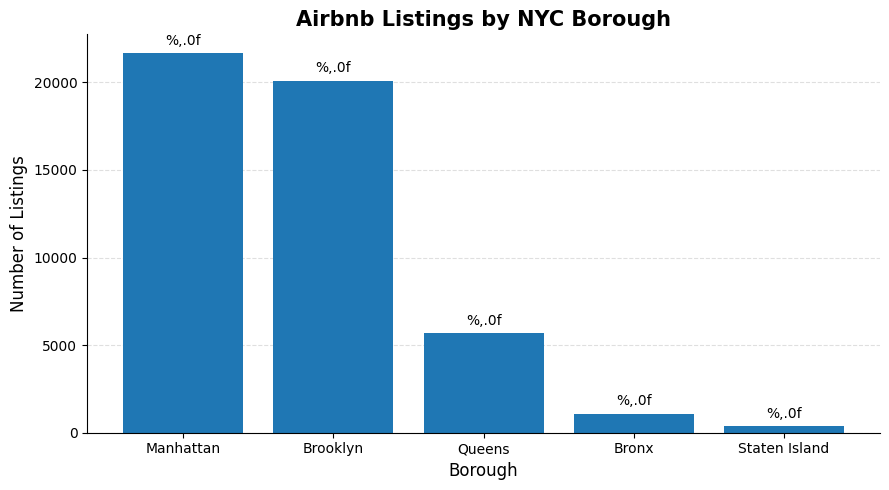

In [24]:
import matplotlib.pyplot as plt

borough_counts = df_cleaned["neighbourhood_group"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(borough_counts.index, borough_counts.values)

ax.set_title("Airbnb Listings by NYC Borough", fontsize=15, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Number of Listings", fontsize=12)
ax.bar_label(bars, fmt="%,.0f", padding=4)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


Mean and Median Airbnb Nightly Price by Borough:


,median_price,mean_price
neighbourhood_group,,
Manhattan,150.0,196.88
Brooklyn,90.0,124.44
Queens,75.0,99.52
Staten Island,75.0,114.81
Bronx,65.0,87.58


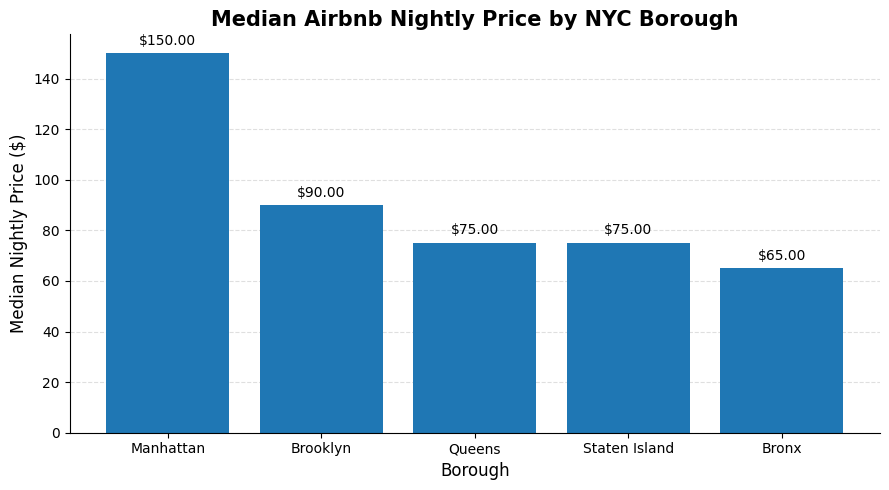

In [25]:
borough_prices = (
    df_cleaned.groupby("neighbourhood_group")["price"]
    .agg(median_price="median", mean_price="mean")
    .sort_values("median_price", ascending=False)
    .round(2)
)

print("Mean and Median Airbnb Nightly Price by Borough:")
display(borough_prices)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(borough_prices.index, borough_prices["median_price"])

ax.set_title("Median Airbnb Nightly Price by NYC Borough",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Median Nightly Price ($)", fontsize=12)
ax.bar_label(bars, labels=[f"${v:,.2f}" for v in borough_prices["median_price"]],
             padding=4)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


### EDA 2: Nightly Prices by Borough

**Business question:** How do Airbnb nightly prices differ across New York City's five boroughs?

**Key findings:**

* Manhattan had the highest median nightly price at $150.
  
* Brooklyn followed at $90.

* Queens and Staten Island both had a median nightly price of $75.

* The Bronx had the lowest median nightly price at $65.

**Interpretation:** Nightly prices varied by borough, with Manhattan showing the highest typical price. The differences between mean and median prices suggest that unusually expensive listings may influence borough averages.

**Methodological note:** Median prices are useful for comparing typical listing prices when distributions are skewed by high-priced properties. These results describe the 2019 dataset and do not establish why the price differences exist.

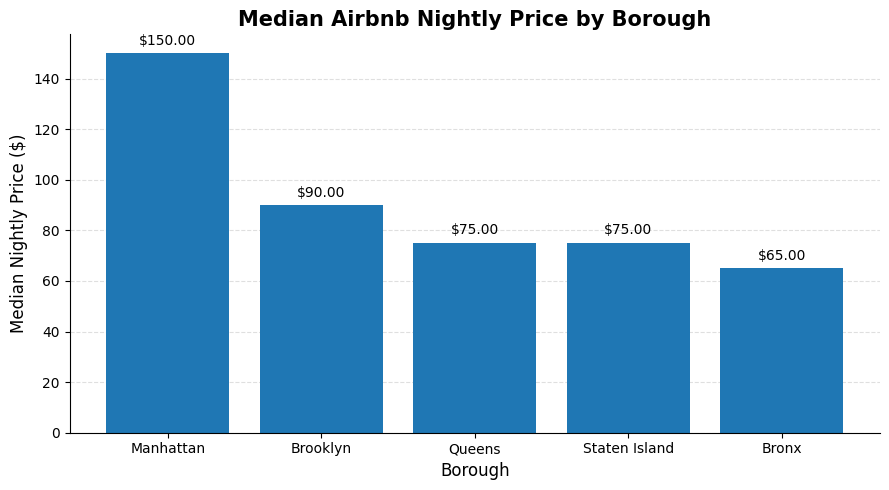

In [26]:
median_prices = (
    df_cleaned.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(median_prices.index, median_prices.values)

ax.set_title("Median Airbnb Nightly Price by Borough",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Median Nightly Price ($)", fontsize=12)

ax.bar_label(
    bars,
    labels=[f"${price:.2f}" for price in median_prices.values],
    padding=4
)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [27]:
room_type_counts = pd.crosstab(
    df_cleaned["neighbourhood_group"],
    df_cleaned["room_type"]
)

room_type_percentages = (
    room_type_counts
    .div(room_type_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

print("Listing Counts by Borough and Room Type:")
display(room_type_counts)

print("Room-Type Percentages Within Each Borough:")
display(room_type_percentages)

Listing Counts by Borough and Room Type:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,379,652,60
Brooklyn,9559,10132,413
Manhattan,13199,7982,480
Queens,2096,3372,198
Staten Island,176,188,9


Room-Type Percentages Within Each Borough:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,34.74,59.76,5.50
Brooklyn,47.55,50.40,2.05
Manhattan,60.93,36.85,2.22
Queens,36.99,59.51,3.49
Staten Island,47.18,50.40,2.41


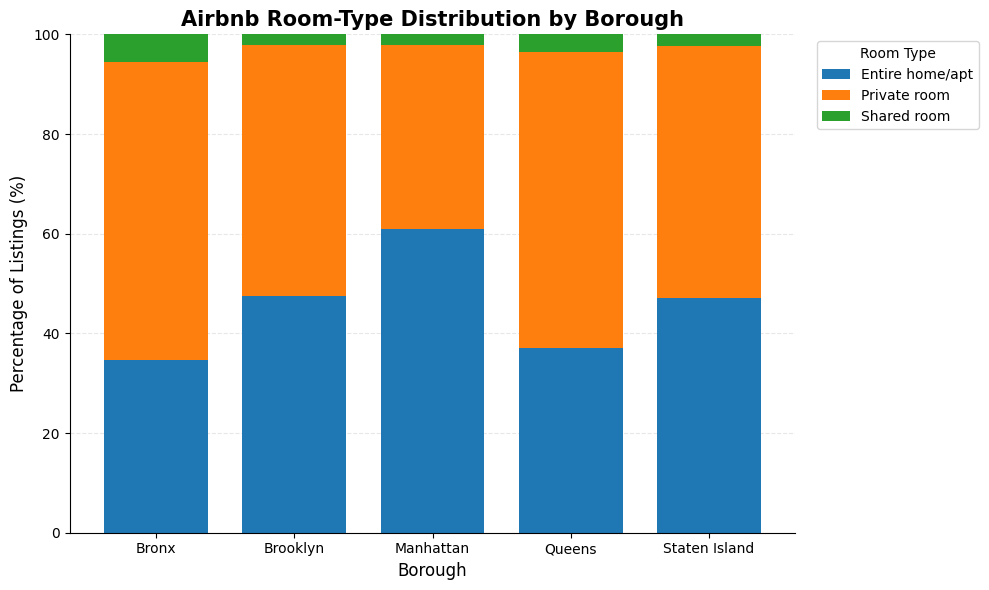

In [28]:
ax = room_type_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Airbnb Room-Type Distribution by Borough",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Percentage of Listings (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.legend(title="Room Type", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


The room-type analysis shows that private rooms are the most common Airbnb listing type in four of New York City's five boroughs. Manhattan differs from this pattern, with entire homes/apartments representing 60.93% of listings. Shared rooms account for the smallest share of listings across all five boroughs.

In [29]:
minimum_nights_summary = (
    df_cleaned.groupby("neighbourhood_group")["minimum_nights"]
    .agg(
        listing_count="count",
        median_minimum_nights="median",
        mean_minimum_nights="mean",
        maximum_minimum_nights="max"
    )
    .sort_values("median_minimum_nights", ascending=False)
    .round(2)
)

print("Minimum-Night Requirements by Borough:")
display(minimum_nights_summary)

Minimum-Night Requirements by Borough:


,listing_count,median_minimum_nights,mean_minimum_nights,maximum_minimum_nights
neighbourhood_group,,,,
Brooklyn,20104,3.0,6.06,999
Manhattan,21661,3.0,8.58,1250
Bronx,1091,2.0,4.56,365
Queens,5666,2.0,5.18,500
Staten Island,373,2.0,4.83,365


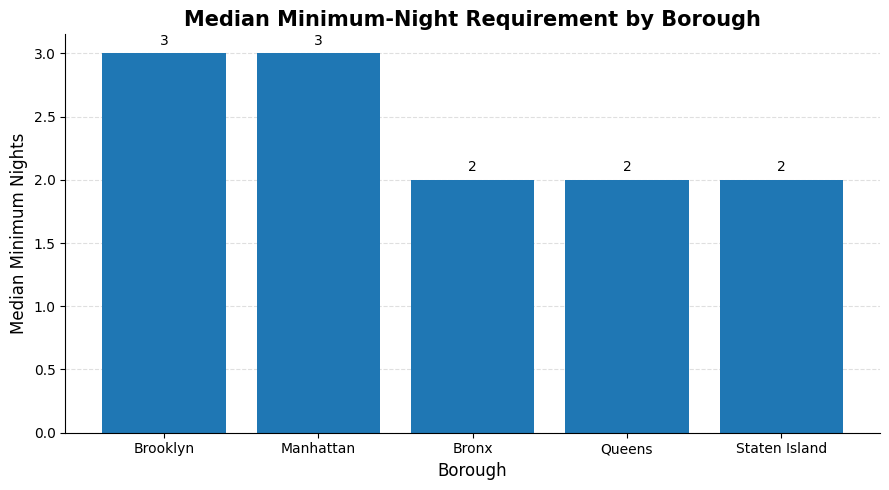

In [30]:
median_nights = (
    df_cleaned.groupby("neighbourhood_group")["minimum_nights"]
    .median()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(median_nights.index, median_nights.values)

ax.set_title("Median Minimum-Night Requirement by Borough",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Median Minimum Nights", fontsize=12)
ax.bar_label(bars, fmt="%.0f", padding=4)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [31]:
review_summary = (
    df_cleaned.groupby("neighbourhood_group")
    .agg(
        listing_count=("id", "count"),
        total_reviews=("number_of_reviews", "sum"),
        median_reviews_per_listing=("number_of_reviews", "median"),
        mean_reviews_per_listing=("number_of_reviews", "mean")
    )
    .sort_values("total_reviews", ascending=False)
    .round(2)
)

print("Review Activity by Borough:")
display(review_summary)

Review Activity by Borough:


,listing_count,total_reviews,median_reviews_per_listing,mean_reviews_per_listing
neighbourhood_group,,,,
Brooklyn,20104,486574,6.0,24.20
Manhattan,21661,454569,4.0,20.99
Queens,5666,156950,7.0,27.70
Bronx,1091,28371,9.0,26.00
Staten Island,373,11541,12.0,30.94


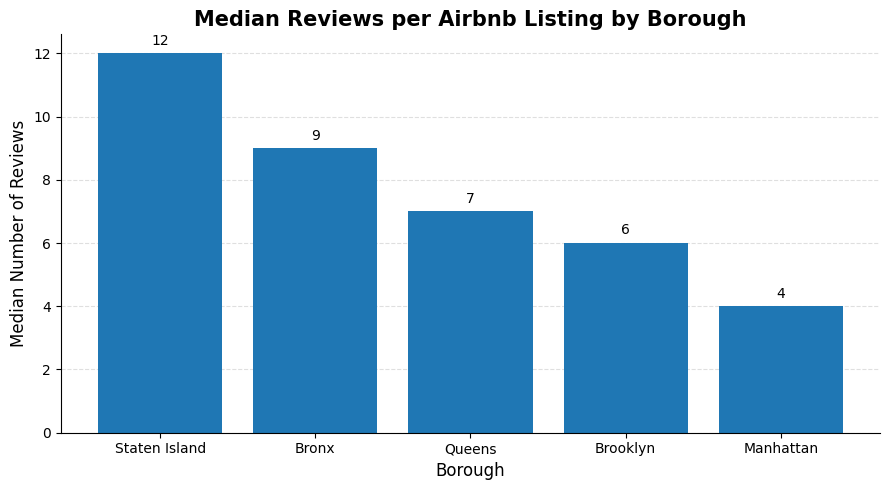

In [32]:
median_reviews = (
    df_cleaned.groupby("neighbourhood_group")["number_of_reviews"]
    .median()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(median_reviews.index, median_reviews.values)

ax.set_title("Median Reviews per Airbnb Listing by Borough",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Borough", fontsize=12)
ax.set_ylabel("Median Number of Reviews", fontsize=12)
ax.bar_label(bars, fmt="%.0f", padding=4)

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Review activity varies across New York City's boroughs. Staten Island has the highest median number of reviews per listing at 12, while Manhattan has the lowest at 4. Brooklyn has the highest total review count, with 486,574 reviews, reflecting its much larger number of listings. These results highlight the difference between overall review volume and typical review activity per listing.

In [33]:
price_summary = df_cleaned["price"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.995]
).round(2)

print("Nightly Airbnb Price Distribution:")
display(price_summary.to_frame(name="price"))


Nightly Airbnb Price Distribution:


,price
count,48884.00
mean,152.76
std,240.17
min,10.00
50%,106.00
75%,175.00
90%,269.00
95%,355.00
99%,799.00
99.5%,1000.00


In [34]:
highest_priced_listings = (
    df_cleaned.loc[
        df_cleaned["price"].notna(),
        ["name", "neighbourhood_group", "room_type", "price", "minimum_nights"]
    ]
    .sort_values("price", ascending=False)
    .head(10)
)

display(highest_priced_listings)


,name,neighbourhood_group,room_type,price,minimum_nights
9151,Furnished room in Astoria apartment,Queens,Private room,10000.0,100
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000.0,5
29238,1-BR Lincoln Center,Manhattan,Entire home/apt,10000.0,30
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999.0,99
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Entire home/apt,9999.0,30
6530,Spanish Harlem Apt,Manhattan,Entire home/apt,9999.0,5
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Entire home/apt,8500.0,30
4377,Film Location,Brooklyn,Entire home/apt,8000.0,1
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Entire home/apt,7703.0,1
45666,Gem of east Flatbush,Brooklyn,Private room,7500.0,1


### Understanding Right-Skewed Prices

**Right-skewed** means most Airbnb listings have lower or moderate nightly prices, while a small number have very high prices.

**In this dataset:**

* Median price: $106

* Mean price: $152.76

* Maximum price: $10,000

The mean is higher than the median because unusually expensive listings pull the average upward.

In [35]:
print("Dataset dimensions:", df_cleaned.shape)

print("\nColumn names and data types:")
display(
    pd.DataFrame({
        "Column": df_cleaned.columns,
        "Data Type": df_cleaned.dtypes.astype(str).values,
        "Missing Values": df_cleaned.isna().sum().values
    })
)

print("\nTotal rows:", len(df_cleaned))
print("Total columns:", len(df_cleaned.columns))

Dataset dimensions: (48895, 16)

Column names and data types:


,Column,Data Type,Missing Values
0,id,int64,0
1,name,object,0
2,host_id,int64,0
3,host_name,object,0
4,neighbourhood_group,object,0
5,neighbourhood,object,0
6,latitude,float64,0
7,longitude,float64,0
8,room_type,object,0
9,price,float64,11



Total rows: 48895
Total columns: 16


In [36]:
output_file = "/kaggle/working/nyc_airbnb_cleaned.csv"

df_cleaned.to_csv(output_file, index=False)

print("Export complete:", output_file)
print("Rows exported:", len(df_cleaned))
print("Columns exported:", len(df_cleaned.columns))

Export complete: /kaggle/working/nyc_airbnb_cleaned.csv
Rows exported: 48895
Columns exported: 16
